# CAS ADS M2 Project - Football Club Survey

**Author:** Cornel Gübeli
**Date:** 2026-10-12

## Initial Remark
Please note that this notebook is my first attempt to coding with real data and is heavily influenced by my good friend GPT 6. I'm very happy about any feedback and eager to learn more. A lot of code seem to be more complicated than they could be...

## Objective
This notebook cleans, explores and analyses data on a survey conducted with 25 Swiss voluntarly football clubs as part of the national initiative "SFV Quality Club". Data was collected between the 01.01.2024 and 31.12.2024. The goal of the initiative is to support and develop voluntary sports clubs in order to harness their societal potential. The survey was sent out by the club to it's members and, in case of minors, their parents. 

## Research Question
RQ: Which clubs have a significantly lower member satisfaction than a reference club we consider "satisfactory"?

## Resources
SFV Quality Club program details: https://org.football.ch/vereinsentwicklung/quality-club.aspx


# Load Packages


In [1]:
# import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

# Data Cleaning
This part of the notebook I would never show in a public repository, as it gives others an insight into the pseudomization process

In [2]:
# import raw data from xlsx file
df = pd.read_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\Gesamtdaten 2024 - SFV Quality Club.xlsx", engine='openpyxl')


In [3]:
#assign labels according to codebook

# 1. Load the original LimeSurvey dataset
df = pd.read_excel("C:\\Users\\guebeli.SPW\\Documents\\Data_CASADS_Projects\\M3_Data_SFV_Survey\\Gesamtdaten 2024 - SFV Quality Club.xlsx")

# 2. Load the first two rows of your completed codebook
codebook = pd.read_excel(
    "C:\\Users\\guebeli.SPW\\Documents\\Data_CASADS_Projects\\M3_Data_SFV_Survey\\Full_Codebook_SFV_Quality_Club_Data.xlsx",
    sheet_name="Tabelle1",
    header=None,
    nrows=2
)

# 3. Extract original headers and new variable names
# Skip column A because it contains descriptions
old_names = codebook.iloc[0, 1:].tolist()
new_names = codebook.iloc[1, 1:].tolist()

# 4. Create mapping dictionary
mapping = dict(zip(old_names, new_names))

# 5. Check for columns not found in the codebook
unmatched = [
    col for col in df.columns
    if col not in mapping
]

if unmatched:
    print("WARNING: The following columns were not found:")
    for col in unmatched:
        print(col)

# 6. Rename columns
df = df.rename(columns=mapping)

# 7. Check for duplicate variable names
if df.columns.duplicated().any():
    raise ValueError("Duplicate variable names detected!")

# 8. Display results
print("\nCOLUMN RENAMING RESULTS")
print("Total columns:", len(df.columns))
print("Columns renamed:", len(df.columns) - len(unmatched))
print("Unmatched columns:", len(unmatched))

# 9. Show dataframe info and first few rows
df.head()



COLUMN RENAMING RESULTS
Total columns: 271
Columns renamed: 271
Unmatched columns: 0


,id,date_sent,last_page,language,random_n,ip,club,tot_sat,strat_part_sat,strat_imp,...,vol_willing_other_text,vol_contact_consent,vol_contact_details,birth_year,education_level,employment_extent,household_income_cat,gender,club_positive_text,club_improvements_text
0,6,NaN,NaN,de,1411403760,104.28.135.84,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7,1980-01-01 00:00:00,18.0,de,979837807,188.61.117.237,FC Raron,zufrieden,weder noch,wichtig,...,NaN,NaN,NaN,1981.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Ich gehe keiner Beschäftigung nach (z.B. in Re...,NaN,Weiblich,NaN,NaN
2,8,1980-01-01 00:00:00,18.0,de,1156841452,178.197.194.117,FC Raron,weder noch,weder noch,sehr wichtig,...,NaN,NaN,NaN,1982.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),115’001-150'000,Männlich,NaN,NaN
3,9,1980-01-01 00:00:00,18.0,de,1617143157,146.136.160.37,FC Münsterlingen,sehr zufrieden,zufrieden,sehr wichtig,...,NaN,NaN,NaN,1998.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Mehr als Vollzeit,Unter 50'000,Männlich,NaN,NaN
4,10,1980-01-01 00:00:00,18.0,de,1708915218,83.76.205.189,FC Raron,sehr zufrieden,zufrieden,sehr wichtig,...,NaN,NaN,NaN,1979.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),80’001-95'000,Männlich,Tradition und Förderung der Junioren,Mithilfe der Mitglieder


In [4]:
# remove private data (IP and Phone Number)
df = df.drop(columns=[
    "ip",
    "vol_contact_details"
])

In [5]:
# pseudonymization of clubs
# 1. Enter the real club names
# Replace each placeholder with the exact name from LimeSurvey

club_names = [
    "BSC Old Boys",
    "CS Italien GE",
    "FC Affoltern am Albis",
    "FC Boudry",
    "FC Embrach",
    "FC Ems",
    "FC Gerzensee",
    "FC Länggasse",
    "FC Münsterlingen",
    "FC Niederlenz",
    "FC Nordstern Basel",
    "FC Raron",
    "FC Rupperswil",
    "FC Seefeld ZH",
    "FC Seuzach",
    "FC Spiez",
    "FC Sursee",
    "FC Tavannes/Tramelan",
    "FC Utzenstorf",
    "FC Venoge",
    "FC Villars-sur-Glâne",
    "FC Wil 1900",
    "Pully Football",
    "SC Emmen",
    "Urania Genève Sport"
]

# 2. Create mapping automatically
club_mapping = {
    name: f"Club {chr(65 + i)}"
    for i, name in enumerate(club_names)
}

# 3. Check for unrecognized clubs
unknown = set(df["club"].dropna()) - set(club_mapping)

if unknown:
    raise ValueError(f"Unknown club names: {sorted(unknown)}")

# 4. Save mapping in a separate Excel file
mapping_df = pd.DataFrame(
    club_mapping.items(),
    columns=["original_club_name", "pseudonym"]
)

mapping_df.to_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_club_mapping_confidential.xlsx",
    index=False
)

# 5. Replace real club names with pseudonyms
df["club"] = df["club"].replace(club_mapping)

# 6. Save the pseudonymized dataset to a new Excel file
df.to_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_pseudonymized_survey.xlsx", index=False)

df.head()

,id,date_sent,last_page,language,random_n,club,tot_sat,strat_part_sat,strat_imp,vision_sat,...,vol_willing_medical,vol_willing_other_text,vol_contact_consent,birth_year,education_level,employment_extent,household_income_cat,gender,club_positive_text,club_improvements_text
0,6,NaN,NaN,de,1411403760,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7,1980-01-01 00:00:00,18.0,de,979837807,Club L,zufrieden,weder noch,wichtig,unzufrieden,...,NaN,NaN,NaN,1981.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Ich gehe keiner Beschäftigung nach (z.B. in Re...,NaN,Weiblich,NaN,NaN
2,8,1980-01-01 00:00:00,18.0,de,1156841452,Club L,weder noch,weder noch,sehr wichtig,unzufrieden,...,NaN,NaN,NaN,1982.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),115’001-150'000,Männlich,NaN,NaN
3,9,1980-01-01 00:00:00,18.0,de,1617143157,Club I,sehr zufrieden,zufrieden,sehr wichtig,sehr zufrieden,...,NaN,NaN,NaN,1998.0,"Hochschulen (Bachelor FH/PH/Uni, Master FH/PH/...",Mehr als Vollzeit,Unter 50'000,Männlich,NaN,NaN
4,10,1980-01-01 00:00:00,18.0,de,1708915218,Club L,sehr zufrieden,zufrieden,sehr wichtig,zufrieden,...,NaN,NaN,NaN,1979.0,"Höhere Berufsbildung (Berufsprüfung, Höhere Fa...",Vollzeit (90-100%),80’001-95'000,Männlich,Tradition und Förderung der Junioren,Mithilfe der Mitglieder


In [ ]:
"""Recode a pseudonymized SFV LimeSurvey export using the horizontal codebook.

You may run this as a .py file or paste the whole file into one Jupyter cell.
The raw dataset and codebook are never overwritten.

Codebook sheet Tabelle1:
    row 2 = renamed variable names
    row 3 = response types / descriptions
    column A = row descriptions (ignored)
"""

from pathlib import Path
import re
import pandas as pd


# ---------------------------------------------------------------------------
# 1. FILE LOCATIONS 
# ---------------------------------------------------------------------------
DATA_DIR = Path(
    r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey"
)

INPUT_FILE = DATA_DIR / "SFV_2024_pseudonymized_survey.xlsx"
CODEBOOK_FILE = DATA_DIR / "Full_Codebook_SFV_Quality_Club_Data.xlsx"
OUTPUT_FILE = DATA_DIR / "SFV_2024_recoded_cleaned.xlsx"
REPORT_FILE = DATA_DIR / "SFV_2024_recoding_report.xlsx"
UNKNOWN_FILE = DATA_DIR / "SFV_2024_recoding_unknown_values.csv"

# Used if date_sent is missing (or missing for individual respondents).
# Leave None if every respondent has a usable date_sent, or set e.g. 2024.
SURVEY_YEAR = None


# ---------------------------------------------------------------------------
# 2. EXACT RESPONSE LABELS IN LIMESURVEY
# ---------------------------------------------------------------------------
SATISFACTION = {
    "sehr unzufrieden": 1,
    "unzufrieden": 2,
    "weder noch": 3,
    "zufrieden": 4,
    "sehr zufrieden": 5,
}

IMPORTANCE = {
    "überhaupt nicht wichtig": 1,
    "nicht wichtig": 2,
    "weder noch": 3,
    "wichtig": 4,
    "sehr wichtig": 5,
}

AGREEMENT = {
    "trifft nicht zu": 1,
    "trifft eher nicht zu": 2,
    "weder noch": 3,
    "trifft eher zu": 4,
    "trifft voll zu": 5,
    "weiss nicht": pd.NA,
}

YES_NO = {"Nein": 0, "Ja": 1, "nein": 0, "ja": 1}
EXIT_THREE_LEVELS = {"Nein": 0, "Ja, manchmal": 1, "Ja, oft": 2}

# Nominal categories: codes are LABELS, NOT numerical ranks.
# Both 'Anderes' (from the codebook) and 'Divers' (from some exports)
# are allowed here as code 2. Adjust these labels if needed.
GENDER = {
    "Weiblich": 0,
    "Männlich": 1,
    "Anderes": 2,
    "Divers": 2,
    "weiblich": 0,
    "männlich": 1,
    "anderes": 2,
    "divers": 2,
}

FOOTBALL_FREQUENCY = {
    "monatlich": 1,
    "zweiwöchentlich": 2,
    "1x pro Woche": 3,
    "2x pro Woche": 4,
    "3x pro Woche": 5,
    "4x pro Woche": 6,
    "5x pro Woche": 7,
    "6x pro Woche": 8,
    "mehr als 6x pro Woche": 9,
}

FOOTBALL_HOURS = {
    "weniger als 1h pro Woche": 1,
    "1-2h pro Woche": 2,
    "2-3h pro Woche": 3,
    "3-4h pro Woche": 4,
    "4-5h pro Woche": 5,
    "5-6h pro Woche": 6,
    "6-7h pro Woche": 7,
    "mehr als 7h pro Woche": 8,
}

VOLUNTEERING_YEARS = {
    "Weniger als 1 Jahr": 1,
    "1-2 Jahre": 2,
    "2-5 Jahre": 3,
    "5-10 Jahre": 4,
    "Über 10 Jahre": 5,
}

VOLUNTEERING_HOURS = {
    "Weniger als 1 Stunde": 1,
    "1-2 Stunden": 2,
    "2-5 Stunden": 3,
    "5-10 Stunden": 4,
    "Über 10 Stunden": 5,
}


# ---------------------------------------------------------------------------
# 3. RECODING RULES
# ---------------------------------------------------------------------------
def allow_existing_numeric_codes(mapping):
    """Accept previously recoded numeric values on repeat runs."""
    extended = mapping.copy()
    for value in mapping.values():
        if isinstance(value, int):
            extended[value] = value
            extended[str(value)] = value
    return extended


def code_for(variable_name, data_type):
    """Return (mapping, description), or (None, description) to preserve a field."""
    t = str(data_type).strip().lower()
    variable = str(variable_name).strip().lower()

    # FIX: Gender is identified by its variable name, regardless of spelling
    # ('categorical' versus 'categorial') and capitalization in the codebook.
    if variable == "gender":
        return GENDER, "Gender (nominal categories)"

    # All free-text fields, including vol_other and child_exit_reason_text.
    if t == "string":
        return None, "Text response (preserved)"

    if variable in {"exit", "child_exit"}:
        return EXIT_THREE_LEVELS, "Three-category exit intention"

    if t.startswith("likert"):
        if '"sehr unzufrieden"' in t:
            return SATISFACTION, "Satisfaction (1-5)"
        if '"überhaupt nicht wichtig"' in t:
            return IMPORTANCE, "Importance (1-5)"
        if '"trifft nicht zu"' in t:
            return AGREEMENT, "Agreement (1-5)"
        raise ValueError(
            f"Unrecognized Likert type in codebook for {variable_name}: {data_type}"
        )

    if t.startswith("binary"):
        return YES_NO, "Binary Yes/No"

    if t.startswith("ordinal"):
        if "monatlich" in t:
            return FOOTBALL_FREQUENCY, "Football frequency (ordered categories)"
        if "weniger als 1h pro woche" in t:
            return FOOTBALL_HOURS, "Football hours (ordered categories)"
        raise ValueError(
            f"Unrecognized ordinal type in codebook for {variable_name}: {data_type}"
        )

    if t.startswith("categorical") or t.startswith("categorial"):
        if "weniger als 1 jahr" in t:
            return VOLUNTEERING_YEARS, "Volunteering years (ordered categories)"
        if "weniger als 1 stunde" in t:
            return VOLUNTEERING_HOURS, "Volunteering hours (ordered categories)"
        if re.search(r'"nein"\s*,\s*"ja"', t):
            return YES_NO, "Binary Yes/No"
        # Other nominal categories are not assigned arbitrary numeric ranks.
        return None, "Nominal categories (preserved)"

    # IDs, dates, existing numeric and other unclassified variables.
    return None, "Preserved (no validated recoding rule)"


# ---------------------------------------------------------------------------
# 4. ADD APPROXIMATE AGE 
# ---------------------------------------------------------------------------
def add_age_from_birth_year(df):
    """Age = submission year - birth year (not exact age without birthday)."""
    if "birth_year" not in df.columns:
        raise ValueError("Column 'birth_year' is missing from the dataset.")
    if "age" in df.columns:
        raise ValueError("Column 'age' already exists; will not overwrite it.")

    birth_year = pd.to_numeric(df["birth_year"], errors="coerce")
    bad_birth = df["birth_year"].notna() & birth_year.isna()
    if bad_birth.any():
        raise ValueError(f"{int(bad_birth.sum())} birth_year values are not numeric.")
    if (birth_year.notna() & (birth_year % 1 != 0)).any():
        raise ValueError("birth_year contains non-integer values.")
    birth_year = birth_year.astype("Int64")

    if "date_sent" in df.columns:
        dates = pd.to_datetime(
            df["date_sent"], errors="coerce", format="mixed", dayfirst=True
        )
        bad_dates = df["date_sent"].notna() & dates.isna()
        if bad_dates.any():
            raise ValueError(f"{int(bad_dates.sum())} date_sent values cannot be parsed.")
        reference_year = dates.dt.year.astype("Int64")
    else:
        reference_year = pd.Series(pd.NA, index=df.index, dtype="Int64")

    if SURVEY_YEAR is not None:
        reference_year = reference_year.fillna(int(SURVEY_YEAR))
    if reference_year.isna().all():
        raise ValueError("No survey year available. Set SURVEY_YEAR above.")

    age = (reference_year - birth_year).astype("Int64")
    if (age.notna() & ((age < 0) | (age > 110))).any():
        raise ValueError("Implausible ages detected: verify birth_year and date_sent.")
    df["age"] = age
    return df


# ---------------------------------------------------------------------------
# 5. EXECUTE RECODING AND SAVE REPORTS
# ---------------------------------------------------------------------------
def main():
    if INPUT_FILE.resolve() == OUTPUT_FILE.resolve():
        raise ValueError("Input and output must have different filenames.")

    df = pd.read_excel(INPUT_FILE)
    codebook = pd.read_excel(
        CODEBOOK_FILE, sheet_name="Tabelle1", header=None, nrows=3
    )
    names = codebook.iloc[1, 1:].tolist()
    types = codebook.iloc[2, 1:].tolist()

    if len(names) != len(set(names)):
        raise ValueError("Duplicate variable names in codebook row 2.")
    specs = dict(zip(names, types))

    matched = [c for c in df.columns if c in specs]
    print(f"Input columns: {df.shape[1]}")
    print(f"Columns matched to codebook: {len(matched)}")
    if not matched:
        raise ValueError(
            "No dataset columns match codebook variable names. "
            "Check that the original question headers were renamed first, "
            "and that CODEBOOK_FILE is the correct workbook."
        )

    audit = []
    unknown_rows = []
    recoded_columns = 0

    for col in df.columns:
        if col not in specs:
            audit.append({"variable": col, "action": "Not in codebook; preserved"})
            continue

        mapping, action = code_for(col, specs[col])
        series = df[col]
        if mapping is None:
            audit.append({
                "variable": col,
                "type_in_codebook": specs[col],
                "action": action,
                "valid_n": int(series.notna().sum()),
                "missing_n": int(series.isna().sum()),
            })
            continue

        mapping = allow_existing_numeric_codes(mapping)
        unknown = series.notna() & ~series.isin(mapping.keys())
        for value, count in series.loc[unknown].value_counts().items():
            unknown_rows.append({
                "variable": col,
                "unexpected_value": value,
                "frequency": int(count),
            })

        audit.append({
            "variable": col,
            "type_in_codebook": specs[col],
            "action": action,
            "valid_n": int(series.notna().sum()),
            "missing_n": int(series.isna().sum()),
            "unknown_n": int(unknown.sum()),
        })

        if not unknown.any():
            df[col] = series.map(mapping).astype("Int64")
            recoded_columns += 1

    if unknown_rows:
        pd.DataFrame(unknown_rows).to_csv(
            UNKNOWN_FILE, index=False, encoding="utf-8-sig"
        )
        pd.DataFrame(audit).to_excel(REPORT_FILE, index=False)
        print(f"Unknown labels found: {len(unknown_rows)} variable/value pairs.")
        print(f"Inspect: {UNKNOWN_FILE}")
        raise ValueError(
            "Recoding halted: unexpected response labels remain. "
            "No new recoded dataset has been saved."
        )

    if recoded_columns == 0:
        raise ValueError(
            "No variables recoded: inspect codebook types and column names."
        )

    # Keep original three-category exit variables AND binary versions.
    for col in ("exit", "child_exit"):
        if col in df.columns:
            df[f"{col}_binary"] = df[col].map({0: 0, 1: 1, 2: 1}).astype("Int64")

    df = add_age_from_birth_year(df)
    audit.append({
        "variable": "age",
        "type_in_codebook": "Derived variable",
        "action": "Submission year minus birth year (approximate)",
        "valid_n": int(df["age"].notna().sum()),
        "missing_n": int(df["age"].isna().sum()),
    })

    df.to_excel(OUTPUT_FILE, index=False)
    pd.DataFrame(audit).to_excel(REPORT_FILE, index=False)
    print(f"Recoding complete: {recoded_columns} variables recoded.")
    print(f"Recoded dataset: {OUTPUT_FILE}")
    print(f"Audit report: {REPORT_FILE}")
    print("Text, IDs, club pseudonyms and other nominal variables were preserved.")


if __name__ == "__main__":
    main()

Input columns: 269
Columns matched to codebook: 269


ValueError: Implausible ages detected: verify birth_year and date_sent.

In [9]:
# create missing values report
missing_report = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing_report = missing_report.sort_values(
    by="missing_pct",
    ascending=False
)

print("\nMISSING VALUES REPORT")
print(missing_report.round(2))

# Save missing-values report
missing_report.to_excel(
    "SFV_2024_missing_values_report.xlsx"
)



MISSING VALUES REPORT
                        missing_n  missing_pct
vol_willing_other_text       6602        99.85
vol_medical_years_cat        6588        99.64
vol_medical_hours_cat        6586        99.61
vol_recruitment_other        6581        99.53
vol_referee_hours_cat        6560        99.21
...                           ...          ...
club                          771        11.66
last_page                     630         9.53
random_n                        0         0.00
language                        0         0.00
id                              0         0.00

[269 rows x 2 columns]


# Selecting relevant data for the analysis
From here I would show the code on a public repository

In [15]:
# select relevant variables for ANOVA

# load data
df_analysis = pd.read_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_recoded_cleaned.xlsx")

# 1. Select relevant variables
columns = [
    "id",
    "club",
    "tot_sat",
    "exit",
    "gender"
]

# 2. Create a reduced DataFrame
df_analysis = df[columns].copy()

# 3. Save the reduced dataset
df_analysis.to_excel(
    "SFV_2024_Club_Comparison.xlsx",
    index=False
)

# 4. Display results
print(df_analysis.head())
print("Number of respondents:", len(df_analysis))
print("Number of variables:", len(df_analysis.columns))

   id    club  tot_sat  exit    gender
0   6     NaN      NaN   NaN       NaN
1   7  Club L      4.0   0.0  Weiblich
2   8  Club L      3.0   0.0  Männlich
3   9  Club I      5.0   0.0  Männlich
4  10  Club L      5.0   0.0  Männlich
Number of respondents: 6612
Number of variables: 5


# Analysis Differences in Member Satisfaction

### Descriptive statistics

This section provides the descriptive statistics and tests the necessary to evaluate if an ANOVA can be run

In [29]:
# overall descriptive statistics for satisfaction

# Select satisfaction values (excluding NaN)
satisfaction = pd.to_numeric(
    df_analysis["tot_sat"], errors="raise"
).dropna()

# Calculate descriptive statistics
mean_sat = satisfaction.mean()
min_sat = satisfaction.min()
max_sat = satisfaction.max()
median_sat = satisfaction.median()

# Print results
print("OVERALL MEMBER SATISFACTION")
print("---------------------------")
print(f"Valid observations: {len(satisfaction)}")
print(f"Mean: {mean_sat:.2f}")
print(f"Median: {median_sat:.2f}")
print(f"Minimum: {min_sat}")
print(f"Maximum: {max_sat}")

OVERALL MEMBER SATISFACTION
---------------------------
Valid observations: 5374
Mean: 3.98
Median: 4.00
Minimum: 1.0
Maximum: 5.0


In [28]:
# 1. Load dataset
df_analysis = pd.read_excel("SFV_2024_Club_Comparison.xlsx")

# 2. Prepare data
data = df_analysis[["club", "tot_sat"]].dropna().copy()
data["tot_sat"] = pd.to_numeric(data["tot_sat"])

# 3. Calculate ranks across all respondents
data["rank"] = data["tot_sat"].rank(method="average")

# 4. Calculate descriptive statistics for each club
club_ranking = data.groupby("club").agg(
    n=("tot_sat", "count"),
    mean_satisfaction=("tot_sat", "mean"),
    median_satisfaction=("tot_sat", "median"),
    mean_rank=("rank", "mean"),
    pct_satisfied=("tot_sat", lambda x: (x >= 4).mean() * 100)
)

# 5. Rank clubs by mean rank (highest first)
club_ranking = club_ranking.sort_values(
    "mean_rank",
    ascending=True
)

# 6. Display complete ranking
print("CLUB SATISFACTION RANKING")
print(club_ranking.round(2))

# 7. Identify highest and lowest clubs
print("\nHIGHEST MEMBER SATISFACTION")
print(club_ranking.tail(1).round(2))

print("\nLOWEST MEMBER SATISFACTION")
print(club_ranking.head(1).round(2))




CLUB SATISFACTION RANKING
          n  mean_satisfaction  median_satisfaction  mean_rank  pct_satisfied
club                                                                         
Club Q  234               3.48                  4.0    1905.16          62.39
Club L  128               3.52                  4.0    2127.34          64.84
Club V  216               3.75                  4.0    2315.06          72.69
Club A  196               3.82                  4.0    2347.47          77.04
Club Y  214               3.74                  4.0    2449.92          74.30
Club F  237               3.96                  4.0    2474.61          81.43
Club S  216               3.99                  4.0    2539.48          85.65
Club J  167               3.95                  4.0    2547.25          83.83
Club C  210               4.01                  4.0    2570.28          84.76
Club R  128               4.02                  4.0    2631.29          83.59
Club H  252               4.04        

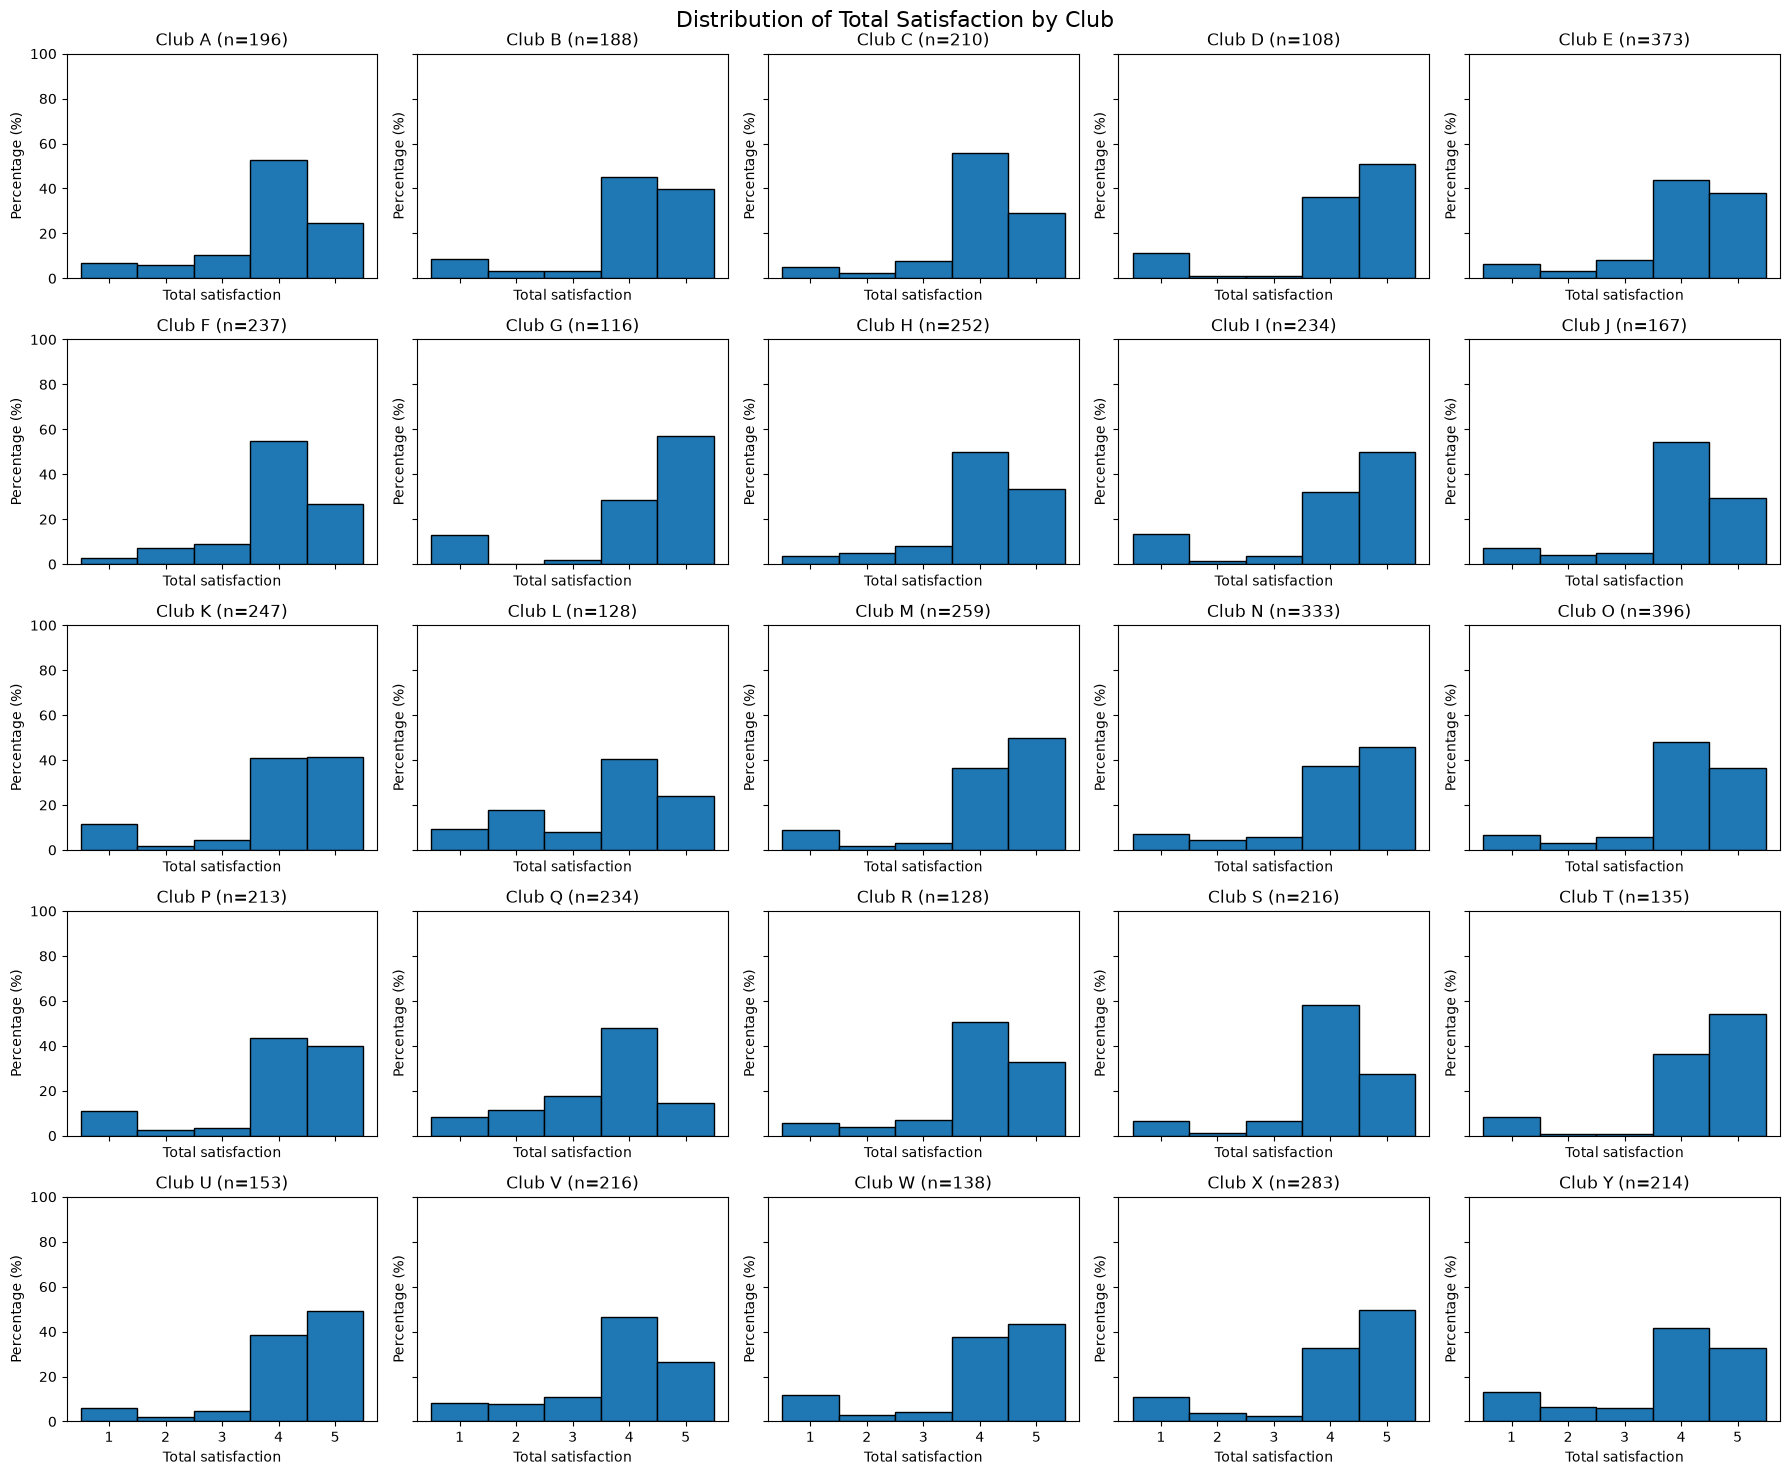

In [24]:
# ensemble histogram for total satisfaction by club

import math

df_analysis = pd.read_excel("SFV_2024_Club_Comparison.xlsx")

# Get club names
clubs = sorted(df_analysis["club"].dropna().unique())

# Create subplot grid
ncols = 5
nrows = math.ceil(len(clubs) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, nrows * 3),
    sharex=True, sharey=True,
    squeeze=False
)

axes = axes.flatten()

# Plot histogram for every club
for ax, club in zip(axes, clubs):

    data = pd.to_numeric(
        df_analysis.loc[
            df_analysis["club"] == club, "tot_sat"
        ].dropna()
    )

    if len(data) > 0:
        ax.hist(
            data,
            bins=np.arange(0.5, 6.5, 1),
            weights=np.ones(len(data)) * 100 / len(data),
            edgecolor="black"
        )

    ax.set_title(f"{club} (n={len(data)})")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_ylim(0, 100)
    ax.set_xlabel("Total satisfaction")
    ax.set_ylabel("Percentage (%)")

# Remove unused subplots
for ax in axes[len(clubs):]:
    ax.set_visible(False)

plt.suptitle(
    "Distribution of Total Satisfaction by Club",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import shapiro

results = []

for club, group in df_analysis.groupby("club"):

    data = group["tot_sat"].dropna()

    if len(data) >= 3:
        stat, p = shapiro(data)

        results.append({
            "club": club,
            "n": len(data),
            "shapiro_w": stat,
            "p_value": p
        })

normality_results = pd.DataFrame(results)

print(normality_results.round(4))

      club    n  shapiro_w  p_value
0   Club A  196     0.7884      0.0
1   Club B  188     0.7119      0.0
2   Club C  210     0.7352      0.0
3   Club D  108     0.6517      0.0
4   Club E  373     0.7570      0.0
5   Club F  237     0.7871      0.0
6   Club G  116     0.6324      0.0
7   Club H  252     0.7710      0.0
8   Club I  234     0.6853      0.0
9   Club J  167     0.7320      0.0
10  Club K  247     0.7150      0.0
11  Club L  128     0.8457      0.0
12  Club M  259     0.6738      0.0
13  Club N  333     0.7284      0.0
14  Club O  396     0.7328      0.0
15  Club P  213     0.7114      0.0
16  Club Q  234     0.8497      0.0
17  Club R  128     0.7513      0.0
18  Club S  216     0.7089      0.0
19  Club T  135     0.6254      0.0
20  Club U  153     0.6894      0.0
21  Club V  216     0.8138      0.0
22  Club W  138     0.7208      0.0
23  Club X  283     0.6946      0.0
24  Club Y  214     0.7804      0.0


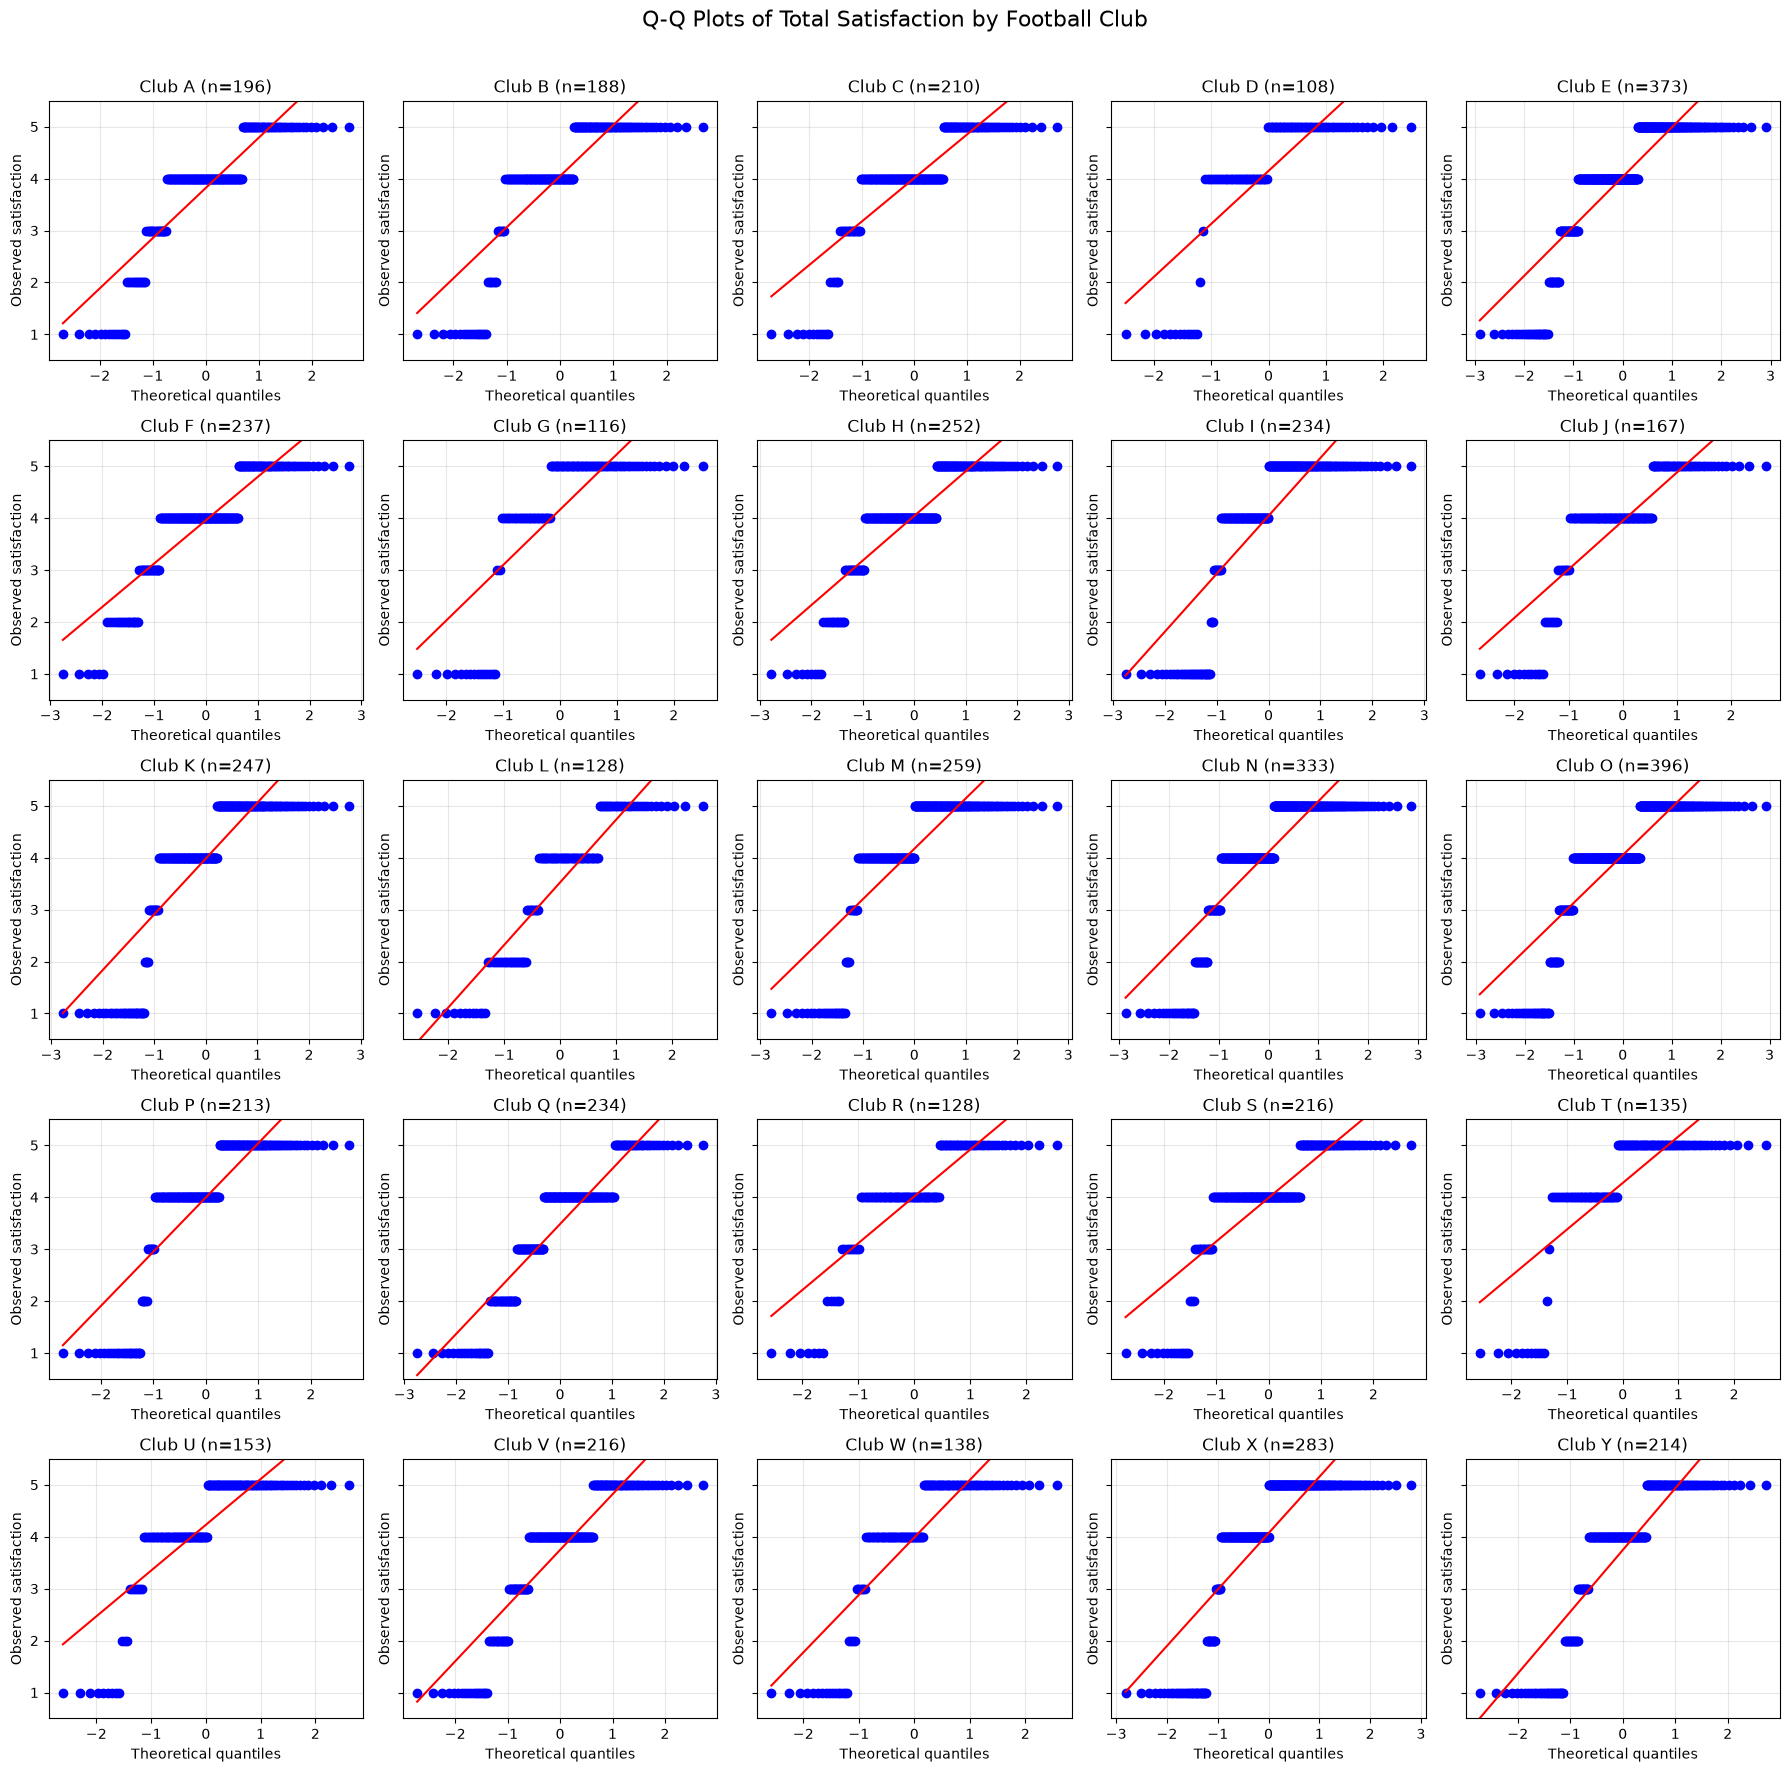

In [20]:
from scipy import stats

# Get all club names
clubs = sorted(df_analysis["club"].dropna().unique())

# Define subplot layout
ncols = 5
nrows = math.ceil(len(clubs) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, nrows * 3.5),
    sharey=True,
    squeeze=False
)

axes = axes.flatten()

# Create one Q-Q plot per club
for ax, club in zip(axes, clubs):

    data = pd.to_numeric(
        df_analysis.loc[
            df_analysis["club"] == club,
            "tot_sat"
        ],
        errors="raise"
    ).dropna()

    if len(data) >= 3:
        stats.probplot(
            data,
            dist="norm",
            plot=ax
        )
    else:
        ax.text(
            0.5, 0.5,
            "Insufficient data",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

    ax.set_title(f"{club} (n={len(data)})")
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel("Observed satisfaction")
    ax.set_ylim(0.5, 5.5)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.grid(alpha=0.3)

# Hide unused subplots
for ax in axes[len(clubs):]:
    ax.set_visible(False)

# Overall title
fig.suptitle(
    "Q-Q Plots of Total Satisfaction by Football Club",
    fontsize=16,
    y=1.01
)

plt.tight_layout()

# Save figure
plt.savefig(
    "qq_plots_tot_sat_by_club.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from scipy.stats import kruskal

# 1. Load dataset
df_analysis = pd.read_excel(r"C:\Users\guebeli.SPW\Documents\Data_CASADS_Projects\M3_Data_SFV_Survey\SFV_2024_recoded_cleaned.xlsx")

# 2. Select relevant variables and remove missing values
data = df_analysis[["club", "tot_sat"]].dropna().copy()

# Ensure satisfaction values are numeric
data["tot_sat"] = pd.to_numeric(
    data["tot_sat"], errors="raise"
)

# 3. Create independent groups for each club
groups = [
    group["tot_sat"].to_numpy()
    for club, group in data.groupby("club")
]

# 4. Run Kruskal-Wallis H test
h_statistic, p_value = kruskal(*groups)

# 5. Display results
print("KRUSKAL-WALLIS H TEST")
print("------------------------------")
print(f"Number of clubs: {len(groups)}")
print(f"Total observations: {len(data)}")
print(f"H statistic: {h_statistic:.4f}")
print(f"p-value: {p_value:.4f}")

# 6. Interpret results
if p_value < 0.05:
    print("\nSignificant differences between clubs (p < 0.05).")
else:
    print("\nNo statistically significant differences detected.")

# 7. Descriptive statistics by club
descriptives = data.groupby("club")["tot_sat"].agg(
    n="count",
    median="median",
    mean="mean",
    std="std"
)

print("\nDESCRIPTIVE STATISTICS BY CLUB")
print(descriptives.round(2))


KRUSKAL-WALLIS H TEST
------------------------------
Number of clubs: 25
Total observations: 5374
H statistic: 216.6787
p-value: 0.0000

Significant differences between clubs (p < 0.05).

DESCRIPTIVE STATISTICS BY CLUB
          n  median  mean   std
club                           
Club A  196     4.0  3.82  1.08
Club B  188     4.0  4.05  1.15
Club C  210     4.0  4.01  0.97
Club D  108     5.0  4.15  1.24
Club E  373     4.0  4.03  1.09
Club F  237     4.0  3.96  0.93
Club G  116     5.0  4.16  1.32
Club H  252     4.0  4.04  0.97
Club I  234     4.5  4.04  1.34
Club J  167     4.0  3.95  1.08
Club K  247     4.0  3.98  1.26
Club L  128     4.0  3.52  1.29
Club M  259     4.0  4.17  1.17
Club N  333     4.0  4.11  1.14
Club O  396     4.0  4.05  1.07
Club P  213     4.0  4.00  1.23
Club Q  234     4.0  3.48  1.14
Club R  128     4.0  4.02  1.03
Club S  216     4.0  3.99  0.99
Club T  135     5.0  4.27  1.12
Club U  153     4.0  4.23  1.05
Club V  216     4.0  3.75  1.18
Club W  138  

In [31]:
import scikit_posthocs as sp

# 1. Load dataset
df_analysis = pd.read_excel("SFV_2024_Club_Comparison.xlsx")

# 2. Prepare data
data = df_analysis[["club", "tot_sat"]].dropna().copy()
data["tot_sat"] = pd.to_numeric(data["tot_sat"])

# 3. Define reference club
reference_club = "Club C"

if reference_club not in data["club"].values:
    raise ValueError("Club C not found in the dataset.")

# 4. Calculate mean ranks across all respondents
data["rank"] = data["tot_sat"].rank(method="average")

mean_ranks = data.groupby("club")["rank"].mean()
medians = data.groupby("club")["tot_sat"].median()
sample_sizes = data.groupby("club")["tot_sat"].count()

# 5. Run Dunn's test (unadjusted p-values)
dunn_results = sp.posthoc_dunn(
    data,
    val_col="tot_sat",
    group_col="club",
    p_adjust=None
)

# 6. Extract comparisons involving Club C
other_clubs = [
    club for club in dunn_results.columns
    if club != reference_club
]

results = pd.DataFrame({
    "Club": other_clubs,
    "n": [sample_sizes[c] for c in other_clubs],
    "Median": [medians[c] for c in other_clubs],
    "Mean_rank": [mean_ranks[c] for c in other_clubs],
    "p_raw": [
        dunn_results.loc[reference_club, c]
        for c in other_clubs
    ]
})

# 7. Apply Holm correction to comparisons with Club C
p = results["p_raw"].to_numpy()
m = len(p)

order = np.argsort(p)
p_sorted = p[order]

p_adjusted = np.minimum(
    1,
    np.maximum.accumulate(
        p_sorted * (m - np.arange(m))
    )
)

p_holm = np.empty(m)
p_holm[order] = p_adjusted

results["p_holm"] = p_holm

# 8. Determine direction and significance
results["Direction"] = np.where(
    results["Mean_rank"] > mean_ranks[reference_club],
    "Higher than Club C",
    np.where(
        results["Mean_rank"] < mean_ranks[reference_club],
        "Lower than Club C",
        "Equal mean rank"
    )
)

results["Significant"] = results["p_holm"] < 0.05

# 9. Sort by adjusted p-value
results = results.sort_values("p_holm")

# 10. Display results
print("DUNN'S POST-HOC TEST: CLUB C VS. ALL CLUBS")
print("-----------------------------------------")
print(f"Club C sample size: {sample_sizes[reference_club]}")
print(f"Club C median: {medians[reference_club]}")
print(f"Club C mean rank: {mean_ranks[reference_club]:.2f}")

print("\nALL COMPARISONS")
print(results.round(4).to_string(index=False))

# 11. Display significant comparisons only
significant = results[results["Significant"]]

print("\nSIGNIFICANT DIFFERENCES FROM CLUB C")
print("----------------------------------")

if significant.empty:
    print("No significant differences found.")
else:
    print(significant.round(4).to_string(index=False))

print("\nAnalysis completed!")


DUNN'S POST-HOC TEST: CLUB C VS. ALL CLUBS
-----------------------------------------
Club C sample size: 210
Club C median: 4.0
Club C mean rank: 2570.28

ALL COMPARISONS
  Club   n  Median  Mean_rank  p_raw  p_holm          Direction  Significant
Club Q 234     4.0  1905.1603 0.0000  0.0000  Lower than Club C         True
Club T 135     5.0  3180.5593 0.0001  0.0028 Higher than Club C         True
Club G 116     5.0  3147.4612 0.0005  0.0117 Higher than Club C         True
Club M 259     4.0  3028.0734 0.0006  0.0130 Higher than Club C         True
Club U 153     4.0  3042.7353 0.0020  0.0405 Higher than Club C         True
Club X 283     4.0  2958.0018 0.0031  0.0592 Higher than Club C        False
Club D 108     5.0  3048.1065 0.0051  0.0913 Higher than Club C        False
Club I 234     4.5  2946.5791 0.0060  0.1016 Higher than Club C        False
Club L 128     4.0  2127.3359 0.0061  0.1016  Lower than Club C        False
Club N 333     4.0  2897.0676 0.0100  0.1502 Higher than Cl

# Visualisation

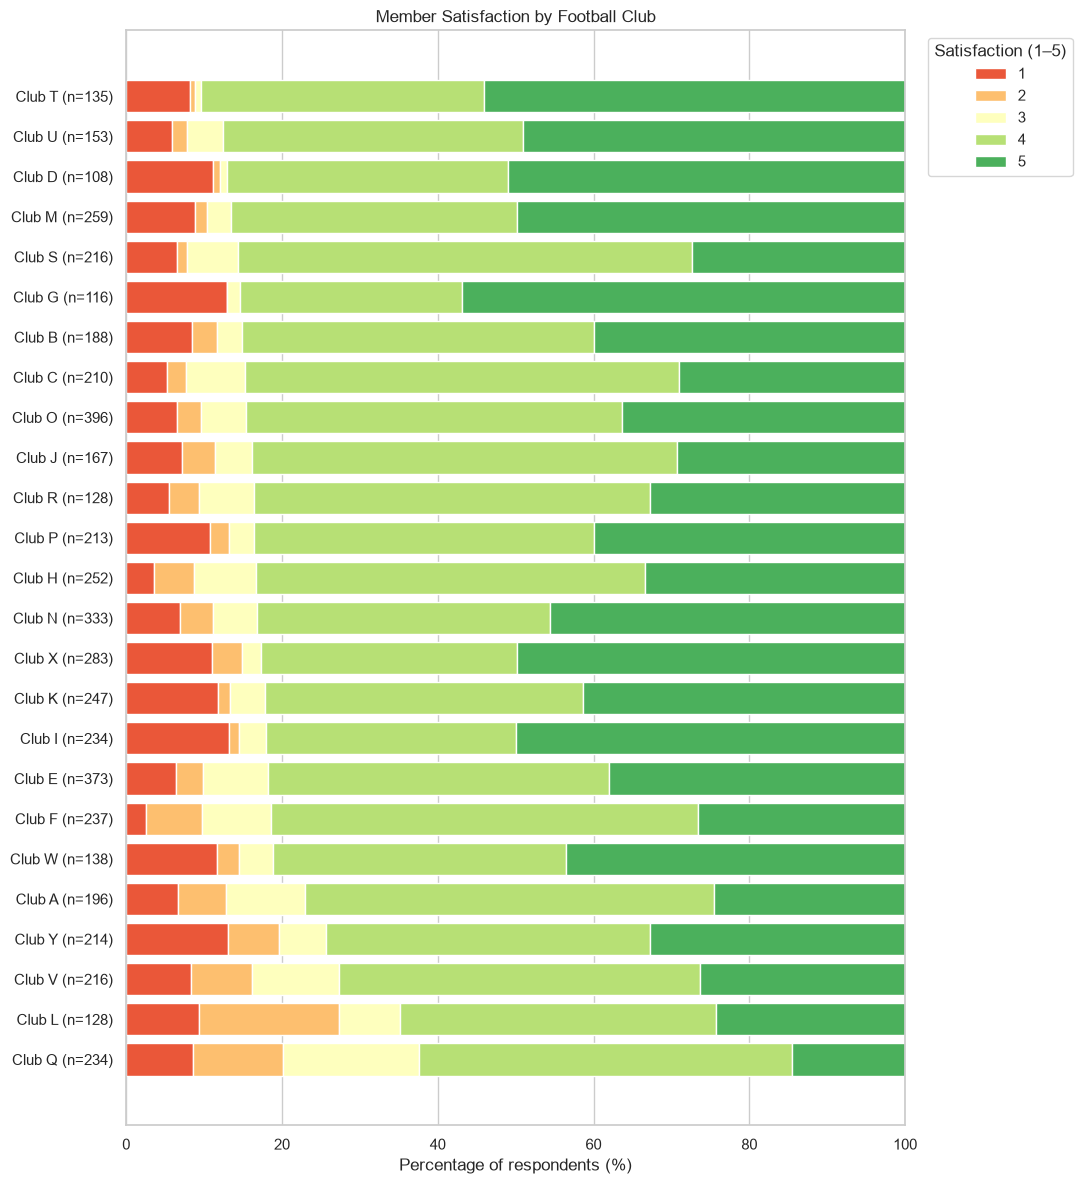

In [32]:
# Visualisation


import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# Load data
data = pd.read_excel("SFV_2024_Club_Comparison.xlsx")[
    ["club", "tot_sat"]
].dropna().copy()

data["tot_sat"] = pd.to_numeric(
    data["tot_sat"], errors="raise"
)

# Check valid Likert values
if not data["tot_sat"].isin([1, 2, 3, 4, 5]).all():
    raise ValueError("Unexpected satisfaction values")

# Calculate frequencies and percentages
counts = pd.crosstab(
    data["club"], data["tot_sat"]
).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)

n = counts.sum(axis=1)
pct = counts.div(n, axis=0) * 100

# Sort clubs by percentage satisfied (4 or 5)
order = (pct[4] + pct[5]).sort_values().index

# Create plot
fig, ax = plt.subplots(figsize=(11, 12))
colors = sns.color_palette("RdYlGn", 5)

left = np.zeros(len(order))

for score in range(1, 6):
    values = pct.loc[order, score].to_numpy()

    ax.barh(
        order, values, left=left,
        color=colors[score - 1],
        label=str(score)
    )
    left += values

ax.set_xlim(0, 100)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([
    f"{club} (n={n.loc[club]})" for club in order
])

ax.set_xlabel("Percentage of respondents (%)")
ax.set_ylabel("")
ax.set_title("Member Satisfaction by Football Club")

ax.legend(
    title="Satisfaction (1–5)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig("satisfaction_likert.png", dpi=300)
plt.show()

